In [ ]:
from google.colab import files

uploaded = files.upload()

Saving india_housing_prices.csv to india_housing_prices.csv


In [ ]:
import pandas as pd

# Read the uploaded CSV into a table called df
df = pd.read_csv("india_housing_prices.csv")

# Display the number of rows and columns
print("Number of properties:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five properties
df.head()

Number of properties: 250000
Number of columns: 23


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [ ]:
# Show column names, data types and non-missing counts
df.info()

# Count missing values in each column
print("\nMissing values in each column:")
print(df.isna().sum())

# Count completely identical rows
print("\nExact duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors    

In [ ]:
# Preserve df as the original dataset
df_clean = df.copy()

print("Working copy created:", df_clean.shape)

Working copy created: (250000, 23)


In [ ]:
# Remove spaces around column names
df_clean.columns = df_clean.columns.str.strip()

# Remove leading and trailing spaces from text values
text_columns = df_clean.select_dtypes(include="object").columns

for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

# Check for empty strings and duplicates after trimming
print("Blank text values:")
print(df_clean[text_columns].eq("").sum())

print(
    "\nDuplicate rows after trimming:",
    df_clean.duplicated().sum()
)

# Exclude the unique ID when checking repeated property details
print(
    "Repeated property details excluding ID:",
    df_clean.drop(columns=["ID"]).duplicated().sum()
)

Blank text values:
State                             0
City                              0
Locality                          0
Property_Type                     0
Furnished_Status                  0
Public_Transport_Accessibility    0
Parking_Space                     0
Security                          0
Amenities                         0
Facing                            0
Owner_Type                        0
Availability_Status               0
dtype: int64

Duplicate rows after trimming: 0
Repeated property details excluding ID: 0


In [ ]:
quality_checks = pd.Series({
    "Duplicate property IDs":
        df_clean["ID"].duplicated().sum(),

    "Zero or negative property prices":
        (df_clean["Price_in_Lakhs"] <= 0).sum(),

    "Zero or negative property sizes":
        (df_clean["Size_in_SqFt"] <= 0).sum(),

    "Zero or negative BHK":
        (df_clean["BHK"] <= 0).sum(),

    "Negative floor numbers":
        (df_clean["Floor_No"] < 0).sum(),

    "Zero or negative total floors":
        (df_clean["Total_Floors"] <= 0).sum(),

    "Floor number higher than total floors":
        (df_clean["Floor_No"] > df_clean["Total_Floors"]).sum(),

    "Negative property ages":
        (df_clean["Age_of_Property"] < 0).sum()
})

print(quality_checks.to_string())

# Display examples of inconsistent floor information
invalid_floors = (
    df_clean["Floor_No"] > df_clean["Total_Floors"]
)

display(
    df_clean.loc[
        invalid_floors,
        ["ID", "Property_Type", "Floor_No", "Total_Floors"]
    ].head()
)

Duplicate property IDs                        0
Zero or negative property prices              0
Zero or negative property sizes               0
Zero or negative BHK                          0
Negative floor numbers                        0
Zero or negative total floors                 0
Floor number higher than total floors    116304
Negative property ages                        0


,ID,Property_Type,Floor_No,Total_Floors
0,1,Apartment,22,1
1,2,Independent House,21,20
4,5,Villa,3,2
5,6,Apartment,27,1
6,7,Independent House,16,5


In [ ]:
# Compare the existing price column with a rupee-based calculation
price_check = df_clean[
    ["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt"]
].head().copy()

price_check["Calculated_Rupees_per_SqFt"] = (
    price_check["Price_in_Lakhs"] * 100000
    / price_check["Size_in_SqFt"]
).round(2)

display(price_check)

# Find the reference year implied by the recorded property ages
print("Reference years implied by Year_Built + Age_of_Property:")

print(
    (df_clean["Year_Built"] + df_clean["Age_of_Property"])
    .value_counts()
    .sort_index()
)

,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Calculated_Rupees_per_SqFt
0,489.76,4740,0.10,10332.49
1,195.52,2364,0.08,8270.73
2,183.79,3642,0.05,5046.40
3,300.29,2741,0.11,10955.49
4,182.90,4823,0.04,3792.25


Reference years implied by Year_Built + Age_of_Property:
2025    250000
Name: count, dtype: int64


In [ ]:
# Preserve the original values for comparison
df_clean["Original_Price_per_SqFt"] = df["Price_per_SqFt"]

# Recalculate price per square foot in rupees
df_clean["Price_per_SqFt"] = (
    df_clean["Price_in_Lakhs"] * 100000
    / df_clean["Size_in_SqFt"]
).round(2)

# Check the corrected values
display(
    df_clean[
        [
            "Price_in_Lakhs",
            "Size_in_SqFt",
            "Original_Price_per_SqFt",
            "Price_per_SqFt"
        ]
    ].head()
)

,Price_in_Lakhs,Size_in_SqFt,Original_Price_per_SqFt,Price_per_SqFt
0,489.76,4740,0.10,10332.49
1,195.52,2364,0.08,8270.73
2,183.79,3642,0.05,5046.40
3,300.29,2741,0.11,10955.49
4,182.90,4823,0.04,3792.25


In [ ]:
# Count inconsistent records using the original dataset
invalid_floor_mask = df["Floor_No"] > df["Total_Floors"]

invalid_floor_count = int(invalid_floor_mask.sum())
invalid_floor_percentage = invalid_floor_mask.mean() * 100

print("Properties with inconsistent floors:", invalid_floor_count)
print(f"Percentage affected: {invalid_floor_percentage:.2f}%")

# Keep a separate table for documenting the issue
floor_issue_records = df.loc[
    invalid_floor_mask,
    ["ID", "Property_Type", "Floor_No", "Total_Floors"]
].copy()

# Remove both unreliable floor fields from the working dataset.
# Also remove the original price-per-sq-ft field:
# the corrected Price_per_SqFt column is already available.
df_clean = df_clean.drop(
    columns=[
        "Floor_No",
        "Total_Floors",
        "Original_Price_per_SqFt"
    ],
    errors="ignore"
)

print("\nRows retained:", len(df_clean))
print("Columns remaining:", df_clean.shape[1])

Properties with inconsistent floors: 116304
Percentage affected: 46.52%

Rows retained: 250000
Columns remaining: 21


In [ ]:
category_columns = [
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

for column in category_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts().to_string())


Property_Type:
Property_Type
Villa                83744
Independent House    83300
Apartment            82956

Furnished_Status:
Furnished_Status
Unfurnished       83408
Semi-furnished    83374
Furnished         83218

Public_Transport_Accessibility:
Public_Transport_Accessibility
High      83705
Low       83287
Medium    83008

Parking_Space:
Parking_Space
No     125456
Yes    124544

Security:
Security
Yes    125233
No     124767

Facing:
Facing
West     62757
North    62637
South    62337
East     62269

Owner_Type:
Owner_Type
Broker     83479
Owner      83268
Builder    83253

Availability_Status:
Availability_Status
Under_Construction    125035
Ready_to_Move         124965


In [ ]:
# Convert each property's amenities into a set.
# This ignores ordering and avoids counting repeated names twice.
amenity_sets = df_clean["Amenities"].apply(
    lambda value: {
        item.strip()
        for item in value.split(",")
        if item.strip()
    }
)

# Find all distinct amenities
amenity_names = sorted(set().union(*amenity_sets))

print("Amenities found:", amenity_names)

# Create one column per amenity: 1 = present, 0 = absent
for amenity in amenity_names:
    column_name = "Has_" + amenity.replace(" ", "_")

    df_clean[column_name] = amenity_sets.apply(
        lambda items: int(amenity in items)
    )

# Count distinct amenities for each property
df_clean["Amenities_Count"] = amenity_sets.apply(len)

amenity_columns = [
    "Has_" + name.replace(" ", "_")
    for name in amenity_names
]

display(
    df_clean[
        ["Amenities"] + amenity_columns + ["Amenities_Count"]
    ].head()
)

print("\nNumber of properties by amenity count:")
print(df_clean["Amenities_Count"].value_counts().sort_index())

Amenities found: ['Clubhouse', 'Garden', 'Gym', 'Playground', 'Pool']


,Amenities,Has_Clubhouse,Has_Garden,Has_Gym,Has_Playground,Has_Pool,Amenities_Count
0,"Playground, Gym, Garden, Pool, Clubhouse",1,1,1,1,1,5
1,"Playground, Clubhouse, Pool, Gym, Garden",1,1,1,1,1,5
2,"Clubhouse, Pool, Playground, Gym",1,0,1,1,1,4
3,"Playground, Clubhouse, Gym, Pool, Garden",1,1,1,1,1,5
4,"Playground, Garden, Gym, Pool, Clubhouse",1,1,1,1,1,5



Number of properties by amenity count:
Amenities_Count
1    50106
2    49806
3    49862
4    50362
5    49864
Name: count, dtype: int64


In [ ]:
numeric_columns = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Year_Built",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals"
]

# Display numerical ranges
display(
    df_clean[numeric_columns].describe().round(2)
)

# Flag potential outliers using the IQR method
outlier_summary = []

for column in [
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt"
]:
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    flagged = (
        (df_clean[column] < lower_limit)
        | (df_clean[column] > upper_limit)
    )

    outlier_summary.append({
        "Column": column,
        "Lower_Limit": round(lower_limit, 2),
        "Upper_Limit": round(upper_limit, 2),
        "Flagged_Rows": int(flagged.sum()),
        "Flagged_Percentage": round(flagged.mean() * 100, 2)
    })

display(pd.DataFrame(outlier_summary))

,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Age_of_Property,Nearby_Schools,Nearby_Hospitals
count,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00,250000.00
mean,3.00,2749.81,254.59,13058.28,2006.52,18.48,5.50,5.50
std,1.42,1300.61,141.35,13071.85,9.81,9.81,2.88,2.87
min,1.00,500.00,10.00,202.25,1990.00,2.00,1.00,1.00
25%,2.00,1623.00,132.55,4802.84,1998.00,10.00,3.00,3.00
50%,3.00,2747.00,253.87,9244.75,2007.00,18.00,5.00,5.00
75%,4.00,3874.00,376.88,15987.39,2015.00,27.00,8.00,8.00
max,5.00,5000.00,500.00,99182.00,2023.00,35.00,10.00,10.00


,Column,Lower_Limit,Upper_Limit,Flagged_Rows,Flagged_Percentage
0,Size_in_SqFt,-1753.50,7250.50,0,0.00
1,Price_in_Lakhs,-233.94,743.38,0,0.00
2,Price_per_SqFt,-11973.99,32764.22,19723,7.89


In [ ]:
# Confirm the number of properties has not changed
assert len(df_clean) == 250000, "Unexpected change in row count"

# Confirm the corrected price-per-square-foot calculation
expected_price_per_sqft = (
    df_clean["Price_in_Lakhs"] * 100000
    / df_clean["Size_in_SqFt"]
).round(2)

assert (
    df_clean["Price_per_SqFt"] - expected_price_per_sqft
).abs().max() < 0.01, "Price-per-square-foot calculation mismatch"

# Confirm amenity indicators match the amenity count
assert (
    df_clean[amenity_columns].sum(axis=1)
    == df_clean["Amenities_Count"]
).all(), "Amenity count mismatch"

print("Validation checks passed.")
print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())

# Save and download a checkpoint
cleaned_filename = "india_housing_prices_cleaned.csv"

df_clean.to_csv(cleaned_filename, index=False)
files.download(cleaned_filename)

Validation checks passed.
Dataset shape: (250000, 27)
Missing values: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Data Cleaning Summary

- The original dataset contains 250,000 properties and 23 columns.
- No missing values, blank text values, duplicate IDs or duplicate
  property records were found in the checks performed.
- Leading and trailing spaces were removed from text fields.
- Price_per_SqFt was recalculated in rupees using:
  (Price_in_Lakhs × 100000) / Size_in_SqFt.
- Property ages were preserved using the dataset's implied
  reference year of 2025.
- Floor_No exceeded Total_Floors in 116,304 records (46.52%).
  Both columns were excluded because the correct values were unknown.
  All property rows were retained.
- Five binary amenity indicators and Amenities_Count were created.
- The IQR method flagged 19,723 records (7.89%) for high price
  per square foot. These records were retained pending further analysis.

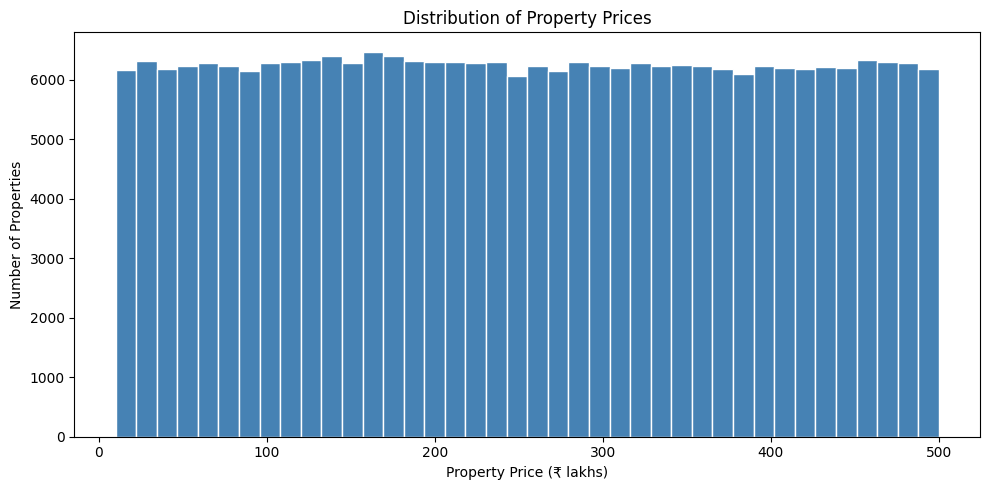

Mean price: 254.59 lakhs
Median price: 253.87 lakhs


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Price_in_Lakhs"],
    bins=40,
    color="steelblue",
    edgecolor="white"
)

plt.title("Distribution of Property Prices")
plt.xlabel("Property Price (₹ lakhs)")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

print(
    "Mean price:",
    round(df_clean["Price_in_Lakhs"].mean(), 2),
    "lakhs"
)

print(
    "Median price:",
    round(df_clean["Price_in_Lakhs"].median(), 2),
    "lakhs"
)

### Observation 1 — Property Price Distribution

Property prices are approximately uniformly distributed between
₹10 lakh and ₹500 lakh. The mean price is ₹254.59 lakh and the
median is ₹253.87 lakh. No narrow price range dominates this dataset.
These findings describe the supplied dataset, not the entire Indian
property market.

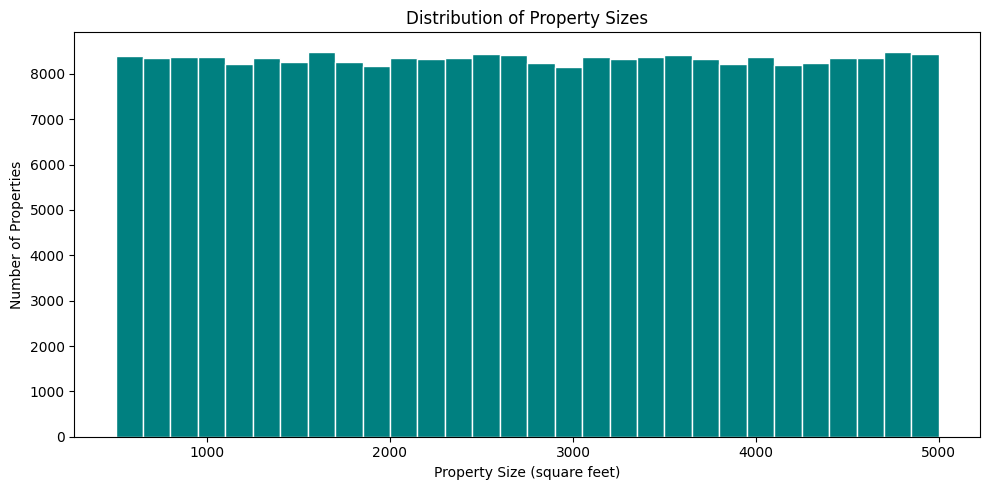

Mean size: 2749.81 sq ft
Median size: 2747.0 sq ft


In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Size_in_SqFt"],
    bins=30,
    color="teal",
    edgecolor="white"
)

plt.title("Distribution of Property Sizes")
plt.xlabel("Property Size (square feet)")
plt.ylabel("Number of Properties")

plt.tight_layout()
plt.show()

print(
    "Mean size:",
    round(df_clean["Size_in_SqFt"].mean(), 2),
    "sq ft"
)

print(
    "Median size:",
    round(df_clean["Size_in_SqFt"].median(), 2),
    "sq ft"
)

,State,City,Property_Count,Mean_Price_Lakhs,Median_Price_Lakhs,Mean_Price_per_SqFt
16,Karnataka,Bangalore,4144,258.46,258.36,13139.52
11,Gujarat,Surat,6167,258.08,258.23,13377.35
19,Kerala,Kochi,6305,257.42,258.75,13202.71
4,Bihar,Gaya,6170,257.05,257.20,13146.40
17,Karnataka,Mangalore,4063,256.92,256.52,13375.35
38,Uttarakhand,Dehradun,6234,256.89,257.03,13006.16
18,Karnataka,Mysore,4217,256.85,259.52,13244.29
32,Tamil Nadu,Chennai,6168,256.83,256.91,13158.76
34,Telangana,Hyderabad,6273,256.59,256.78,13228.64
33,Tamil Nadu,Coimbatore,6461,256.50,255.68,13107.27


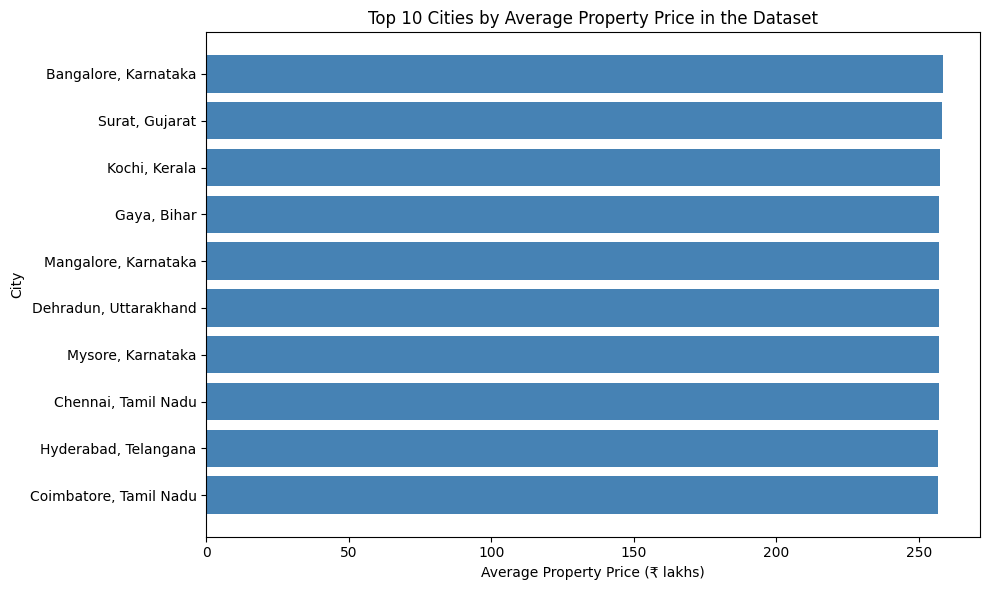

In [ ]:
# Include State so cities are identified unambiguously
city_summary = (
    df_clean.groupby(["State", "City"])
    .agg(
        Property_Count=("ID", "count"),
        Mean_Price_Lakhs=("Price_in_Lakhs", "mean"),
        Median_Price_Lakhs=("Price_in_Lakhs", "median"),
        Mean_Price_per_SqFt=("Price_per_SqFt", "mean")
    )
    .reset_index()
    .sort_values("Mean_Price_Lakhs", ascending=False)
)

display(city_summary.round(2))

# Plot the 10 cities with the highest average listed price
top_cities = city_summary.head(10).sort_values("Mean_Price_Lakhs")

city_labels = top_cities["City"] + ", " + top_cities["State"]

plt.figure(figsize=(10, 6))

plt.barh(
    city_labels,
    top_cities["Mean_Price_Lakhs"],
    color="steelblue"
)

plt.title("Top 10 Cities by Average Property Price in the Dataset")
plt.xlabel("Average Property Price (₹ lakhs)")
plt.ylabel("City")
plt.xlim(left=0)

plt.tight_layout()
plt.show()

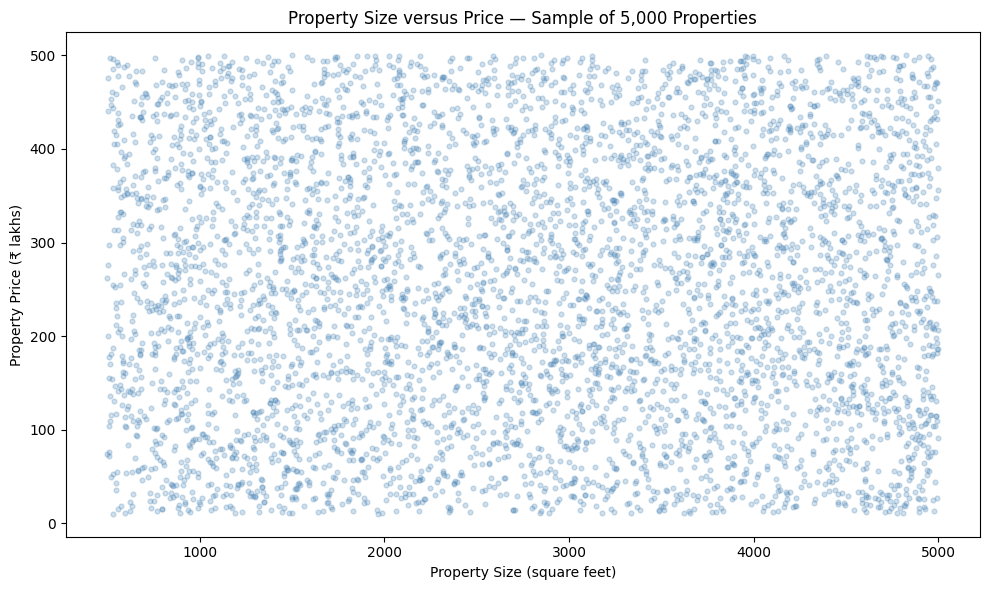

Correlation between size and price: -0.0025


In [ ]:
# Use a reproducible sample for the chart
plot_sample = df_clean.sample(n=5000, random_state=42)

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_sample["Size_in_SqFt"],
    plot_sample["Price_in_Lakhs"],
    alpha=0.25,
    s=12,
    color="steelblue"
)

plt.title("Property Size versus Price — Sample of 5,000 Properties")
plt.xlabel("Property Size (square feet)")
plt.ylabel("Property Price (₹ lakhs)")

plt.tight_layout()
plt.show()

# Calculate correlation using the complete dataset
size_price_correlation = df_clean["Size_in_SqFt"].corr(
    df_clean["Price_in_Lakhs"]
)

print(
    "Correlation between size and price:",
    round(size_price_correlation, 4)
)

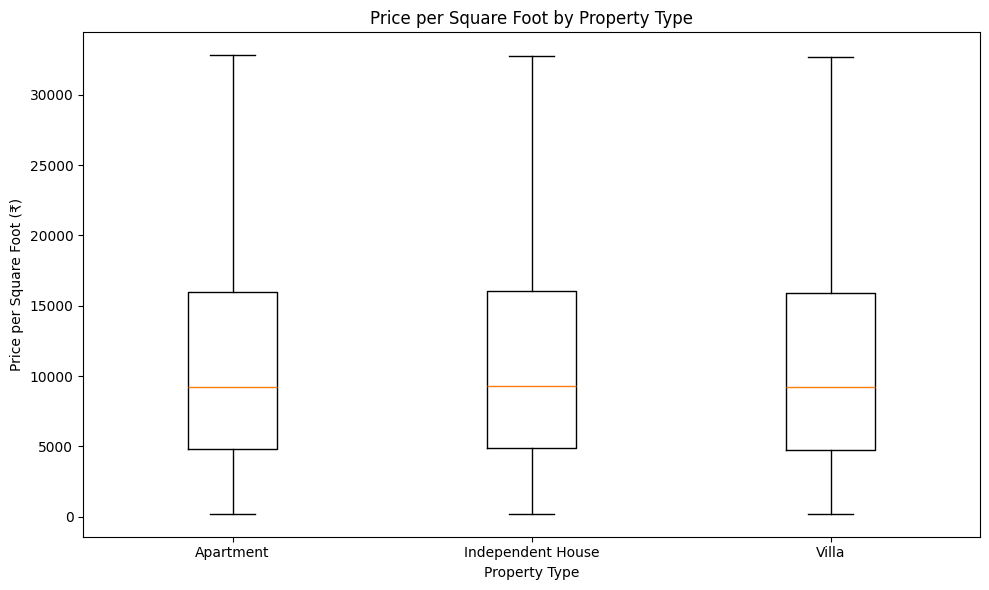

,Property_Count,Median_Price_per_SqFt,Mean_Price_per_SqFt
Property_Type,,,
Apartment,82956,9244.51,13047.32
Independent House,83300,9304.86,13102.05
Villa,83744,9190.26,13025.61


In [ ]:
property_types = sorted(df_clean["Property_Type"].unique())

price_groups = [
    df_clean.loc[
        df_clean["Property_Type"] == property_type,
        "Price_per_SqFt"
    ].to_numpy()
    for property_type in property_types
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(price_groups, showfliers=False)
ax.set_xticks(range(1, len(property_types) + 1))
ax.set_xticklabels(property_types)

ax.set_title("Price per Square Foot by Property Type")
ax.set_xlabel("Property Type")
ax.set_ylabel("Price per Square Foot (₹)")

plt.tight_layout()
plt.show()

# Display summary values using every record
property_type_summary = (
    df_clean.groupby("Property_Type")
    .agg(
        Property_Count=("ID", "count"),
        Median_Price_per_SqFt=("Price_per_SqFt", "median"),
        Mean_Price_per_SqFt=("Price_per_SqFt", "mean")
    )
    .round(2)
)

display(property_type_summary)

### Observation — Property Size Distribution

Property sizes are approximately uniformly distributed between
500 and 5,000 square feet. The mean is 2,749.81 square feet,
and the median is 2,747 square feet.

### Observation — Average Property Price by City

Across the 42 city groups, average property prices range from
₹250.79 lakh in Cuttack to ₹258.46 lakh in Bangalore.

The difference between the highest and lowest averages is
₹7.67 lakh, approximately 3.06% of the lowest average.
City averages are therefore relatively similar in this dataset.

These are comparisons of listed prices, not price growth over
time or evidence that one city is a better investment.


Summary by Furnished_Status:


,count,mean,median
Furnished_Status,,,
Unfurnished,83408,254.98,254.19
Semi-furnished,83374,254.33,253.81
Furnished,83218,254.45,253.56



Summary by Public_Transport_Accessibility:


,count,mean,median
Public_Transport_Accessibility,,,
Low,83287,254.86,254.27
Medium,83008,253.97,252.73
High,83705,254.92,254.71



Summary by Amenities_Count:


,count,mean,median
Amenities_Count,,,
1,50106,254.75,254.21
2,49806,253.97,252.74
3,49862,254.63,253.64
4,50362,254.66,254.07
5,49864,254.92,254.80


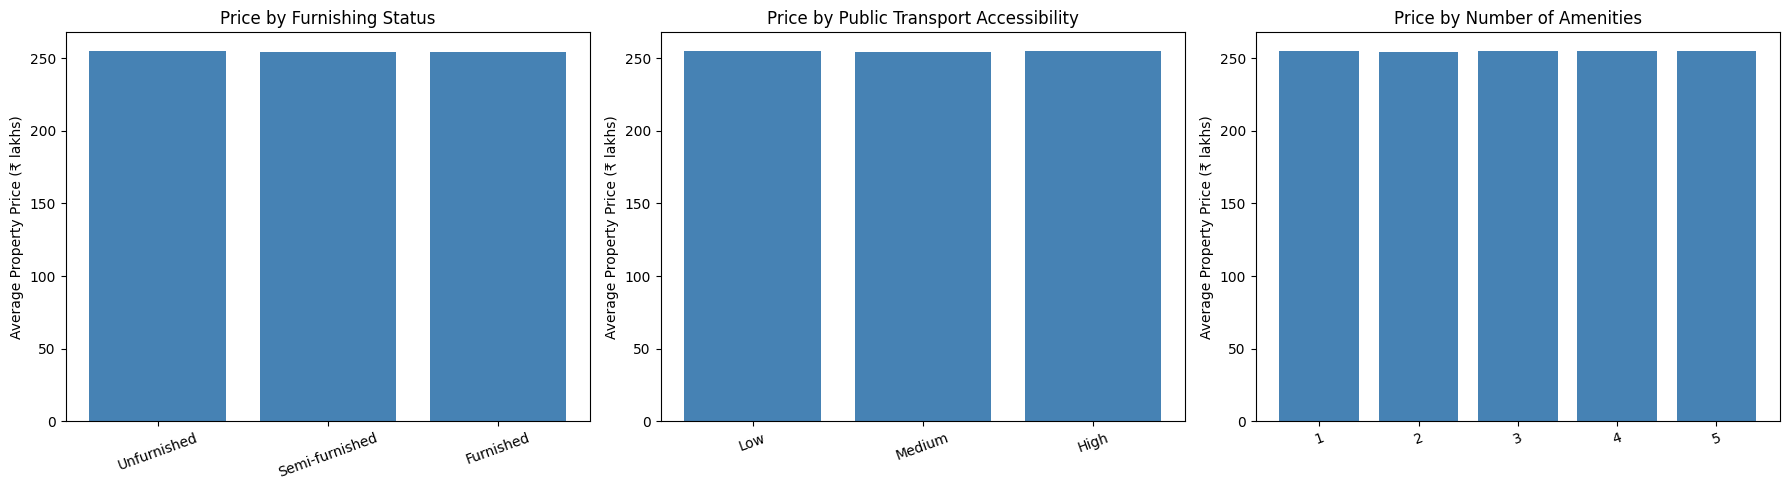

In [ ]:
# Use explicit category orders to make charts easier to read
comparisons = [
    (
        "Furnished_Status",
        ["Unfurnished", "Semi-furnished", "Furnished"],
        "Price by Furnishing Status"
    ),
    (
        "Public_Transport_Accessibility",
        ["Low", "Medium", "High"],
        "Price by Public Transport Accessibility"
    ),
    (
        "Amenities_Count",
        [1, 2, 3, 4, 5],
        "Price by Number of Amenities"
    )
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (column, order, title) in zip(axes, comparisons):
    summary = (
        df_clean.groupby(column)["Price_in_Lakhs"]
        .agg(["count", "mean", "median"])
        .reindex(order)
    )

    ax.bar(
        summary.index.astype(str),
        summary["mean"],
        color="steelblue"
    )

    ax.set_title(title)
    ax.set_ylabel("Average Property Price (₹ lakhs)")
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", labelrotation=20)

    print(f"\nSummary by {column}:")
    display(summary.round(2))

plt.tight_layout()
plt.show()

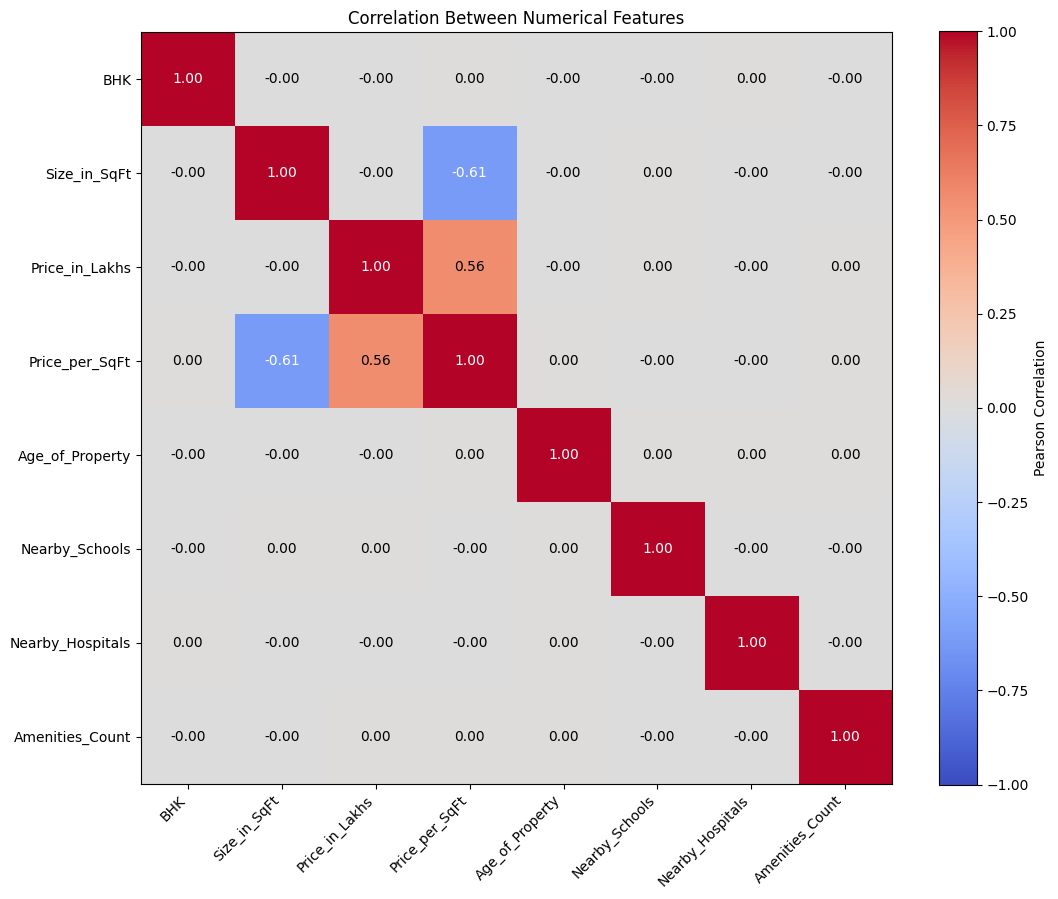

Correlations with property price:
Price_per_SqFt      0.5558
Amenities_Count     0.0010
Nearby_Schools      0.0002
BHK                -0.0010
Size_in_SqFt       -0.0025
Age_of_Property    -0.0027
Nearby_Hospitals   -0.0028
Name: Price_in_Lakhs, dtype: float64


In [ ]:
correlation_columns = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Price_per_SqFt",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Amenities_Count"
]

correlation_matrix = df_clean[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(11, 9))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))

ax.set_xticklabels(
    correlation_columns,
    rotation=45,
    ha="right"
)
ax.set_yticklabels(correlation_columns)

# Write correlation values inside the cells
for row in range(len(correlation_columns)):
    for column in range(len(correlation_columns)):
        value = correlation_matrix.iloc[row, column]

        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

fig.colorbar(heatmap, ax=ax, label="Pearson Correlation")
ax.set_title("Correlation Between Numerical Features")

plt.tight_layout()
plt.show()

print("Correlations with property price:")
print(
    correlation_matrix["Price_in_Lakhs"]
    .drop("Price_in_Lakhs")
    .sort_values(ascending=False)
    .round(4)
)

### Observation — Furnishing Transport and Amenities

Average prices are similar across furnishing categories, public
transport accessibility levels and amenity counts. These comparisons
show no substantial difference in average prices across these groups.

### Observation — Numerical Correlations

BHK, property size, property age, nearby schools, nearby hospitals
and amenity count have near-zero Pearson correlations with price.
This indicates little linear association, but does not rule out
nonlinear relationships.

Price_per_SqFt has a correlation of 0.5558 with price. Since it is
calculated using price, this relationship is partly mathematical.

,Property_Count,Mean_Price_per_SqFt,Median_Price_per_SqFt
State,,,
Punjab,12516,12931.49,9178.13
Rajasthan,12402,12932.17,9186.20
Delhi,12552,12941.35,9180.34
Jharkhand,12480,12975.46,9220.00
Kerala,12487,12982.22,9173.28
Uttarakhand,12501,13027.09,9201.85
Chhattisgarh,12456,13027.13,9142.06
Odisha,12681,13032.92,9185.74
Bihar,12369,13050.62,9218.09


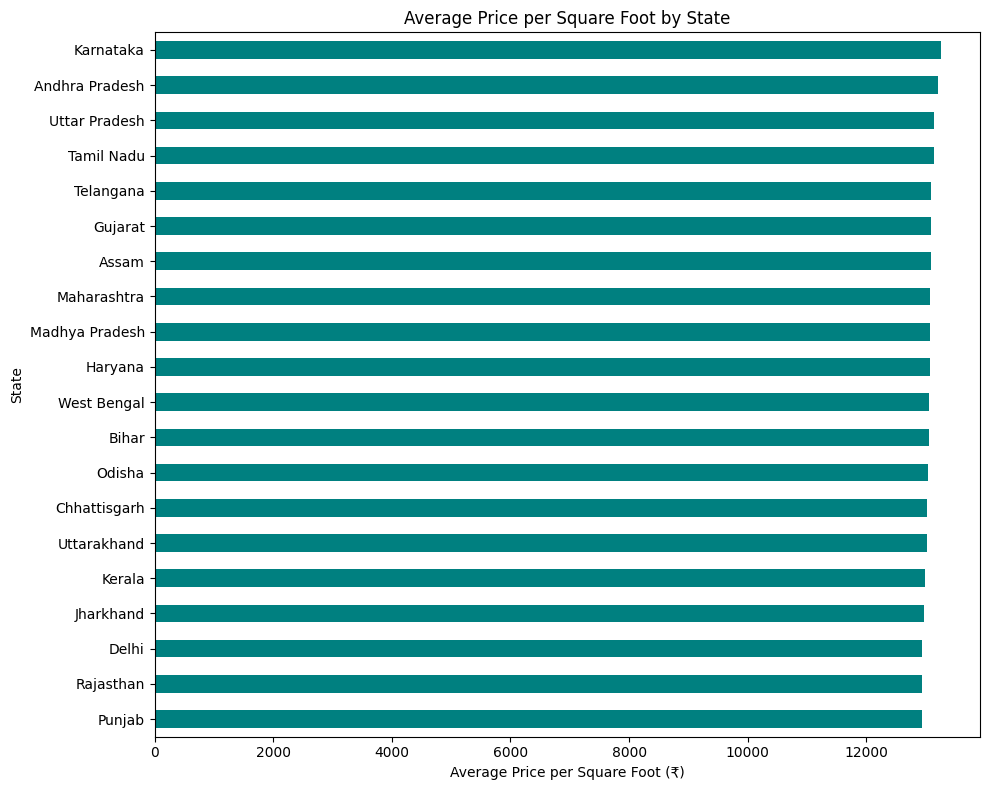

In [ ]:
state_summary = (
    df_clean.groupby("State")
    .agg(
        Property_Count=("ID", "count"),
        Mean_Price_per_SqFt=("Price_per_SqFt", "mean"),
        Median_Price_per_SqFt=("Price_per_SqFt", "median")
    )
    .sort_values("Mean_Price_per_SqFt")
)

display(state_summary.round(2))

state_summary["Mean_Price_per_SqFt"].plot(
    kind="barh",
    figsize=(10, 8),
    color="teal"
)

plt.title("Average Price per Square Foot by State")
plt.xlabel("Average Price per Square Foot (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()


Summary by Nearby_Schools:


,count,mean,median
Nearby_Schools,,,
1,25360,13061.49,9260.54
2,24851,13123.02,9291.49
3,25045,13073.09,9273.34
4,24739,12888.08,9258.67
5,25023,12993.00,9187.98
6,24824,13292.36,9351.67
7,24808,13041.21,9232.54
8,25290,12953.43,9144.04
9,24823,13102.99,9264.53



Summary by Nearby_Hospitals:


,count,mean,median
Nearby_Hospitals,,,
1,25075,13019.83,9256.41
2,24960,13024.68,9309.12
3,24834,13233.68,9348.72
4,25168,12995.99,9270.74
5,25102,12917.02,9148.83
6,25082,13006.56,9128.70
7,24887,13256.91,9334.33
8,24891,13116.32,9223.89
9,25014,13084.28,9283.42


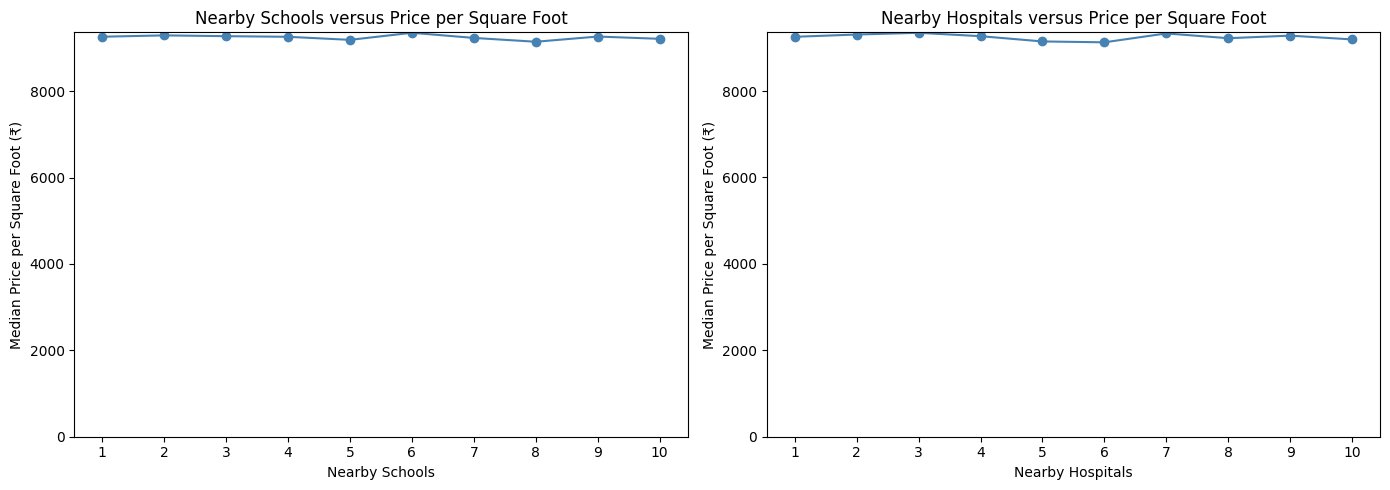

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column, title in [
    (
        axes[0],
        "Nearby_Schools",
        "Nearby Schools versus Price per Square Foot"
    ),
    (
        axes[1],
        "Nearby_Hospitals",
        "Nearby Hospitals versus Price per Square Foot"
    )
]:
    summary = (
        df_clean.groupby(column)["Price_per_SqFt"]
        .agg(["count", "mean", "median"])
    )

    ax.plot(
        summary.index,
        summary["median"],
        marker="o",
        color="steelblue"
    )

    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " "))
    ax.set_ylabel("Median Price per Square Foot (₹)")
    ax.set_xticks(summary.index)
    ax.set_ylim(bottom=0)

    print(f"\nSummary by {column}:")
    display(summary.round(2))

plt.tight_layout()
plt.show()

### Observation — Schools and Hospitals

Median prices per square foot remain relatively similar across
nearby school and hospital counts. Neither comparison shows a
consistent increasing or decreasing pattern.

### Observation — State Comparison

Average prices per square foot range from ₹12,931.49 in Punjab
to ₹13,252.20 in Karnataka, a difference of approximately 2.48%.

Mean prices per square foot exceed medians in every state,
consistent with high values pulling the averages upward.
These results describe the supplied dataset.


Owner_Type:


,Property_Count
Owner_Type,
Broker,83479
Owner,83268
Builder,83253



Availability_Status:


,Property_Count
Availability_Status,
Under_Construction,125035
Ready_to_Move,124965


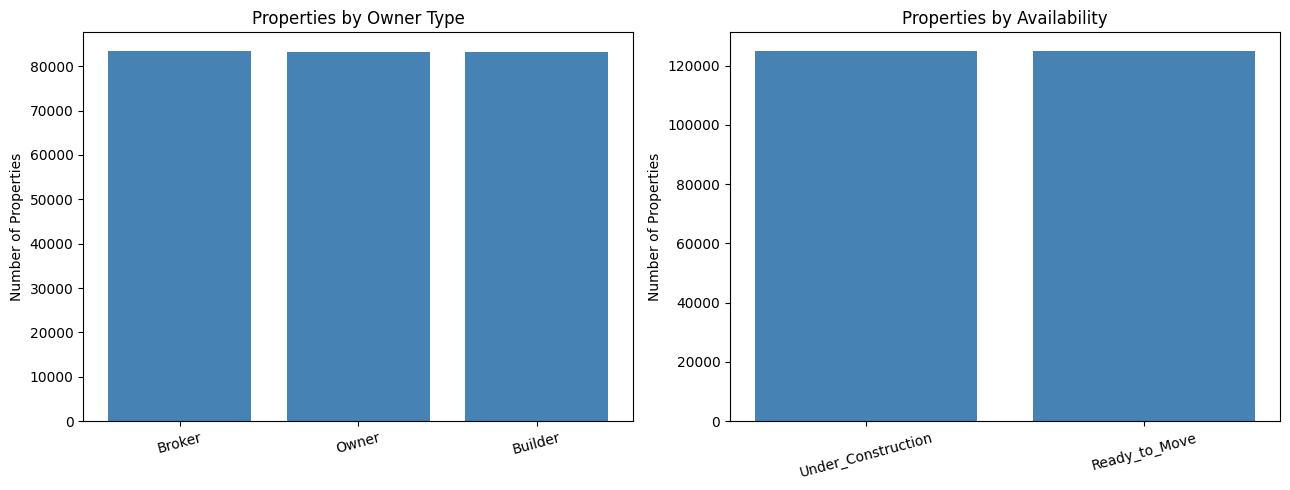

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column, title in [
    (axes[0], "Owner_Type", "Properties by Owner Type"),
    (axes[1], "Availability_Status", "Properties by Availability")
]:
    counts = df_clean[column].value_counts()

    ax.bar(counts.index, counts.values, color="steelblue")
    ax.set_title(title)
    ax.set_ylabel("Number of Properties")
    ax.tick_params(axis="x", labelrotation=15)

    print(f"\n{column}:")
    display(counts.rename("Property_Count").to_frame())

plt.tight_layout()
plt.show()


Summary by Parking_Space:


,Property_Count,Mean_Price_Lakhs,Median_Price_per_SqFt
Parking_Space,,,
No,125456,254.43,9245.36
Yes,124544,254.75,9244.59



Summary by Facing:


,Property_Count,Mean_Price_Lakhs,Median_Price_per_SqFt
Facing,,,
North,62637,254.73,9219.23
South,62337,254.08,9224.63
East,62269,254.49,9234.01
West,62757,255.04,9307.59


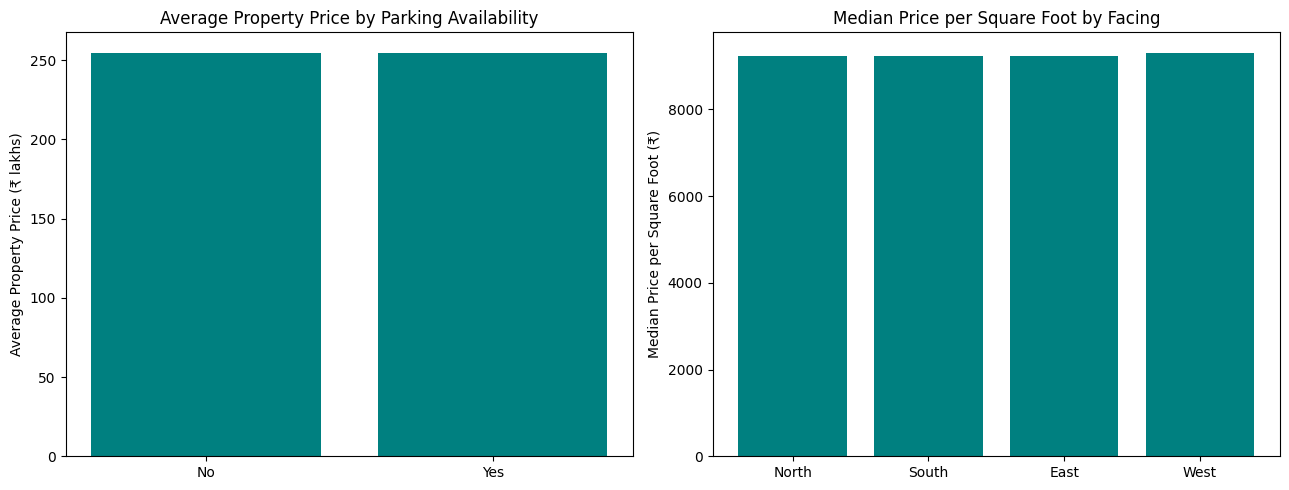

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, column, order, title in [
    (
        axes[0],
        "Parking_Space",
        ["No", "Yes"],
        "Average Property Price by Parking Availability"
    ),
    (
        axes[1],
        "Facing",
        ["North", "South", "East", "West"],
        "Median Price per Square Foot by Facing"
    )
]:
    summary = (
        df_clean.groupby(column)
        .agg(
            Property_Count=("ID", "count"),
            Mean_Price_Lakhs=("Price_in_Lakhs", "mean"),
            Median_Price_per_SqFt=("Price_per_SqFt", "median")
        )
        .reindex(order)
    )

    if column == "Parking_Space":
        values = summary["Mean_Price_Lakhs"]
        ylabel = "Average Property Price (₹ lakhs)"
    else:
        values = summary["Median_Price_per_SqFt"]
        ylabel = "Median Price per Square Foot (₹)"

    ax.bar(summary.index, values, color="teal")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)

    print(f"\nSummary by {column}:")
    display(summary.round(2))

plt.tight_layout()
plt.show()

### Observation — Ownership and Availability

Broker, owner and builder records are approximately equally
represented. Under-construction and ready-to-move properties
each account for approximately half of the dataset.

### Observation — Parking and Facing

Properties with parking have an average price of ₹254.75 lakh,
compared with ₹254.43 lakh without parking. The observed
difference is small.

Median prices per square foot are similar across facing
directions, ranging from ₹9,219.23 to ₹9,307.59.
These comparisons do not establish causal effects.

Sample of locality age summaries:


,State,City,Locality,Property_Count,Median_Age,Mean_Price_Lakhs,Median_Price_Lakhs
0,Andhra Pradesh,Vijayawada,Locality_1,9,18.0,274.84,269.49
1,Andhra Pradesh,Vijayawada,Locality_10,10,19.5,196.59,179.28
2,Andhra Pradesh,Vijayawada,Locality_100,17,16.0,257.85,262.05
3,Andhra Pradesh,Vijayawada,Locality_101,8,28.5,290.53,367.58
4,Andhra Pradesh,Vijayawada,Locality_102,15,15.0,274.13,294.25
5,Andhra Pradesh,Vijayawada,Locality_103,11,17.0,349.25,372.36
6,Andhra Pradesh,Vijayawada,Locality_104,11,21.0,223.62,259.42
7,Andhra Pradesh,Vijayawada,Locality_105,18,22.0,236.01,228.74
8,Andhra Pradesh,Vijayawada,Locality_106,14,21.0,239.57,232.42
9,Andhra Pradesh,Vijayawada,Locality_107,22,22.0,226.22,164.94



Top locality groups by average price (at least 20 properties):


,State,City,Locality,Property_Count,Median_Age,Mean_Price_Lakhs,Median_Price_Lakhs
9563,Kerala,Kochi,Locality_156,20,19.0,340.56,373.32
18207,Uttar Pradesh,Lucknow,Locality_287,21,18.0,331.34,331.49
400,Andhra Pradesh,Vijayawada,Locality_46,21,17.0,330.64,365.75
6722,Haryana,Gurgaon,Locality_3,20,24.5,327.06,365.66
17192,Telangana,Hyderabad,Locality_273,21,21.0,323.89,364.67


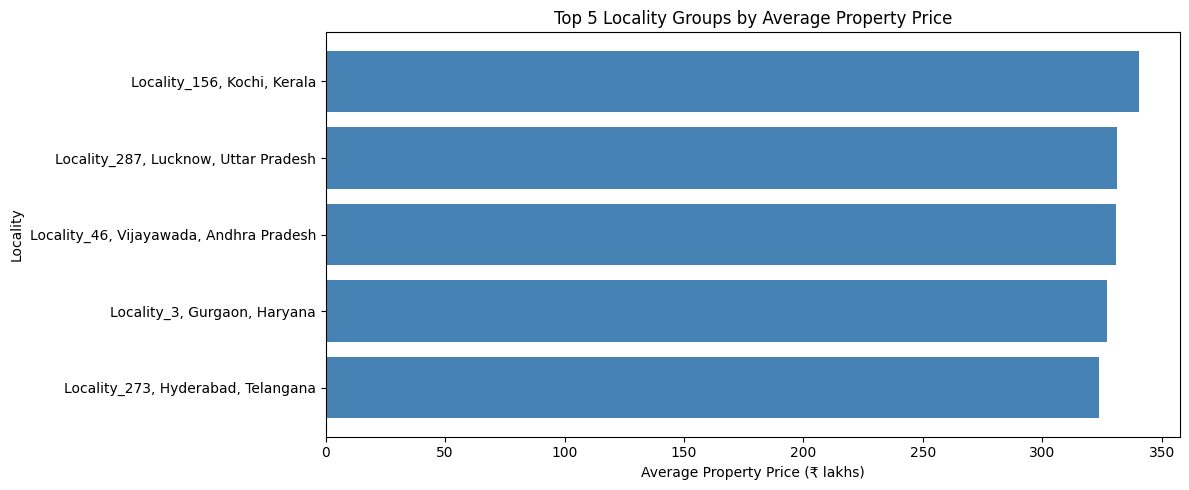

In [ ]:
locality_summary = (
    df_clean.groupby(["State", "City", "Locality"])
    .agg(
        Property_Count=("ID", "count"),
        Median_Age=("Age_of_Property", "median"),
        Mean_Price_Lakhs=("Price_in_Lakhs", "mean"),
        Median_Price_Lakhs=("Price_in_Lakhs", "median")
    )
    .reset_index()
)

print("Sample of locality age summaries:")
display(locality_summary.head(10).round(2))

# Require at least 20 records for a more stable comparison.
# This is a reporting choice, not a guarantee of reliability.
eligible_localities = locality_summary[
    locality_summary["Property_Count"] >= 20
]

top_localities = eligible_localities.nlargest(
    5, "Mean_Price_Lakhs"
)

print("\nTop locality groups by average price (at least 20 properties):")
display(top_localities.round(2))

if not top_localities.empty:
    plot_data = top_localities.sort_values("Mean_Price_Lakhs")

    labels = (
        plot_data["Locality"] + ", "
        + plot_data["City"] + ", "
        + plot_data["State"]
    )

    plt.figure(figsize=(12, 5))
    plt.barh(labels, plot_data["Mean_Price_Lakhs"], color="steelblue")

    plt.title("Top 5 Locality Groups by Average Property Price")
    plt.xlabel("Average Property Price (₹ lakhs)")
    plt.ylabel("Locality")
    plt.xlim(left=0)

    plt.tight_layout()
    plt.show()
else:
    print("No locality groups meet the minimum count of 20.")

BHK                                1      2      3      4      5
State          City                                             
Andhra Pradesh Vijayawada      18.98  20.30  20.37  21.04  19.31
               Vishakhapatnam  18.99  20.51  19.43  21.49  19.57
Assam          Guwahati        20.35  19.01  20.88  19.50  20.26
               Silchar         19.38  19.60  20.67  19.49  20.86
Bihar          Gaya            21.98  20.41  18.57  19.11  19.94
               Patna           20.16  19.52  19.18  20.42  20.71
Chhattisgarh   Bilaspur        19.32  19.99  20.36  20.25  20.09
               Raipur          19.47  20.65  20.17  20.02  19.68
Delhi          Dwarka          20.73  19.39  19.98  19.47  20.43
               New Delhi       20.57  18.78  20.62  20.31  19.73
Gujarat        Ahmedabad       19.72  19.76  19.84  19.62  21.06
               Surat           20.58  19.17  20.56  20.24  19.46
Haryana        Faridabad       19.48  19.95  20.44  19.68  20.44
               Gurgaon         20.20  19.87  20.16  20.05  19.72
Jharkhand      Jamshedpur      20.11  19.27  20.90  20.09  19.62
               Ranchi          20.08  19.79  19.61  20.18  20.34
Karnataka      Bangalore       20.25  19.86  19.35  20.10  20.44
               Mangalore       20.33  20.35  19.27  20.55  19.49
               Mysore          20.51  19.73  19.78  20.44  19.54
Kerala         Kochi           20.14  20.11  19.14  20.30  20.30
               Trivandrum      20.54  19.46  21.01  19.17  19.82
Madhya Pradesh Bhopal          19.70  19.65  19.97  20.04  20.64
               Indore          20.50  19.67  19.75  20.19  19.90
Maharashtra    Mumbai          19.72  19.52  20.99  20.20  19.57
               Nagpur          20.22  19.30  20.38  19.59  20.50
               Pune            21.35  19.27  19.93  19.70  19.74
Odisha         Bhubaneswar     19.55  20.45  20.54  19.25  20.21
               Cuttack         20.76  20.32  20.46  19.44  19.02
Punjab         Amritsar        20.64  19.92  19.84  19.68  19.93
               Ludhiana        20.38  19.09  20.56  19.54  20.43
Rajasthan      Jaipur          19.71  20.25  19.85  20.49  19.69
               Jodhpur         20.32  19.98  20.16  19.14  20.40
Tamil Nadu     Chennai         20.48  19.97  19.18  20.38  19.99
               Coimbatore      19.13  20.14  20.38  20.82  19.53
Telangana      Hyderabad       18.97  20.92  20.02  20.26  19.83
               Warangal        20.03  20.40  19.18  19.89  20.51
Uttar Pradesh  Lucknow         20.52  20.59  20.19  19.14  19.56
               Noida           19.98  20.04  19.95  19.02  21.00
Uttarakhand    Dehradun        19.86  20.81  19.65  20.02  19.67
               Haridwar        19.67  20.58  19.63  19.51  20.60
West Bengal    Durgapur        20.53  19.71  20.15  19.73  19.88
               Kolkata         20.11  20.32  19.82  19.26  20.48

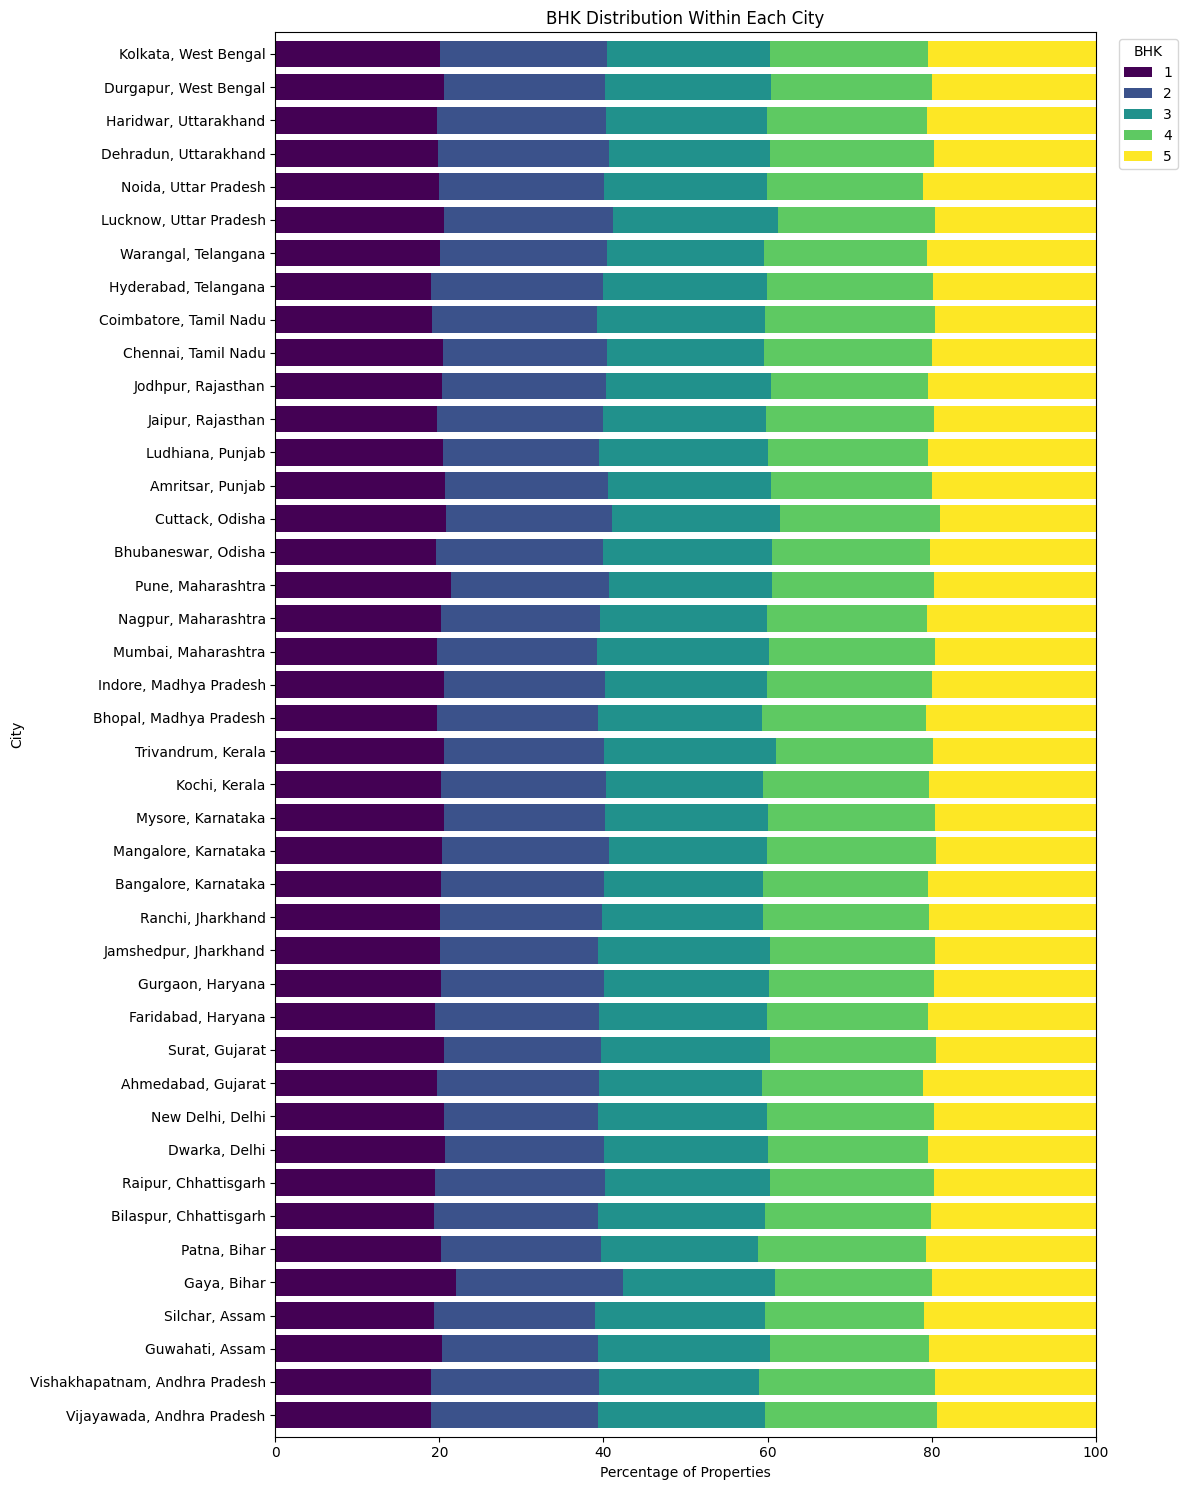

In [ ]:
bhk_counts = pd.crosstab(
    index=[df_clean["State"], df_clean["City"]],
    columns=df_clean["BHK"]
).reindex(columns=[1, 2, 3, 4, 5], fill_value=0)

bhk_percentages = (
    bhk_counts.div(bhk_counts.sum(axis=1), axis=0) * 100
)

display(bhk_percentages.round(2))

# Include state in the chart labels
plot_data = bhk_percentages.copy()
plot_data.index = [
    f"{city}, {state}"
    for state, city in plot_data.index
]

ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 15),
    colormap="viridis",
    width=0.8
)

ax.set_title("BHK Distribution Within Each City")
ax.set_xlabel("Percentage of Properties")
ax.set_ylabel("City")
ax.set_xlim(0, 100)
ax.legend(title="BHK", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Observation — BHK Distribution

Within each city, 1–5 BHK properties each account for approximately
20% of listings. No BHK category strongly dominates.

### Observation — Locality Analysis

Among locality groups containing at least 20 properties,
Locality_156 in Kochi has the highest average listed price
at ₹340.56 lakh.

The five highest-ranked groups contain only 20–21 properties
each. Their averages should be interpreted cautiously because
small groups can be influenced by a few expensive listings.

Median property age was calculated for each state-city-locality
group using the dataset's 2025 age reference.


Price per square foot by Furnished_Status:
                  Property_Count  Mean_Price_per_SqFt  Median_Price_per_SqFt
Furnished_Status                                                            
Unfurnished                83408             13047.86                9283.38
Semi-furnished             83374             13093.13                9227.38
Furnished                  83218             13033.82                9234.83

Price per square foot by Amenities_Count:
                 Property_Count  Mean_Price_per_SqFt  Median_Price_per_SqFt
Amenities_Count                                                            
1                         50106             13015.00                9240.31
2                         49806             13059.41                9241.96
3                         49862             13044.05                9206.72
4                         50362             13070.87                9249.82
5                         49864             13102.17                9293

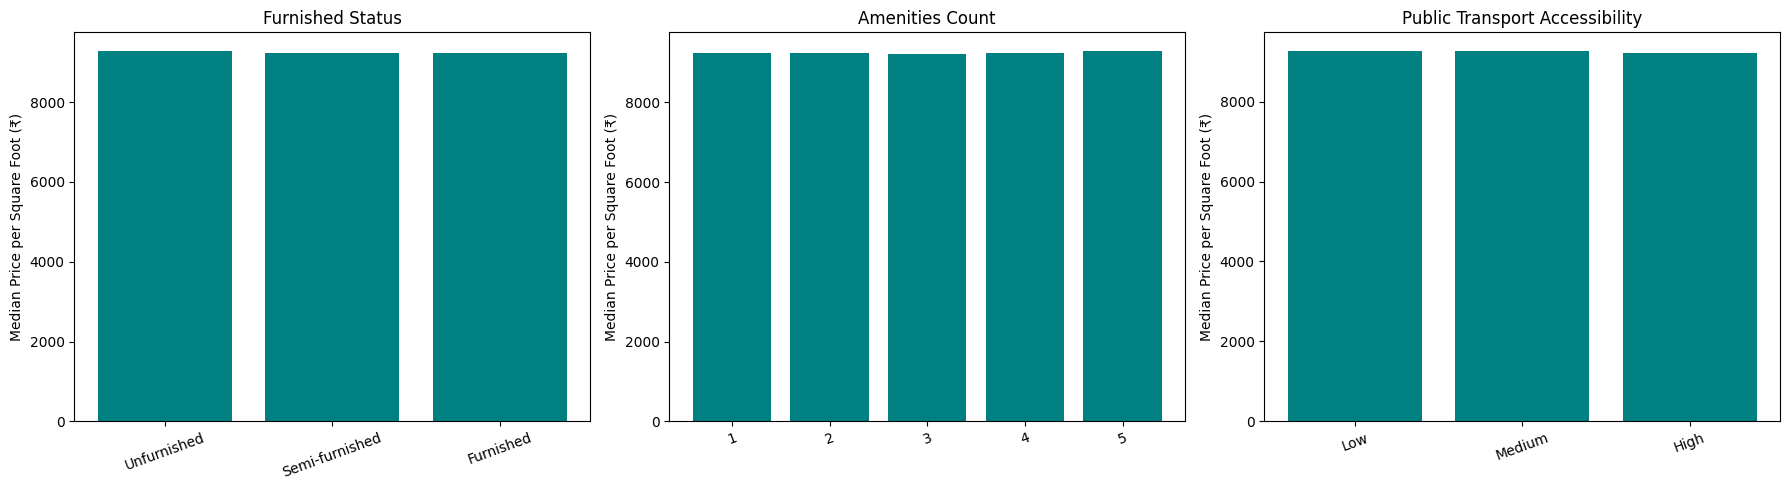

In [ ]:
comparisons = [
    (
        "Furnished_Status",
        ["Unfurnished", "Semi-furnished", "Furnished"]
    ),
    (
        "Amenities_Count",
        [1, 2, 3, 4, 5]
    ),
    (
        "Public_Transport_Accessibility",
        ["Low", "Medium", "High"]
    )
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (column, order) in zip(axes, comparisons):
    summary = (
        df_clean.groupby(column)
        .agg(
            Property_Count=("ID", "count"),
            Mean_Price_per_SqFt=("Price_per_SqFt", "mean"),
            Median_Price_per_SqFt=("Price_per_SqFt", "median")
        )
        .reindex(order)
    )

    ax.bar(
        summary.index.astype(str),
        summary["Median_Price_per_SqFt"],
        color="teal"
    )

    ax.set_title(column.replace("_", " "))
    ax.set_ylabel("Median Price per Square Foot (₹)")
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", labelrotation=20)

    print(f"\nPrice per square foot by {column}:")
    print(summary.round(2).to_string())

plt.tight_layout()
plt.show()

### Dataset Limitations

The dataset contains no sale-date history, observed five-year
future prices or realised investment returns. Historical price
trends and actual investment returns cannot be measured.

Crime rate, infrastructure score and RERA status are absent.
Year_Built represents construction year, not the date when a
property price was recorded.

Any future-price targets or investment labels created for this
project must therefore be explicitly documented as assumptions
or rules rather than observed outcomes.

### Observation — Additional Price per Square Foot Comparisons

Median prices per square foot are similar across furnishing,
amenity-count and public-transport categories. No consistent
increase is observed as amenities or transport accessibility rise.
These findings describe the supplied dataset.

In [ ]:
from sklearn.model_selection import train_test_split

# 70% training; 30% reserved for validation and testing
train_df, remaining_df = train_test_split(
    df_clean,
    test_size=0.30,
    random_state=42
)

# Divide the remaining 30% equally
validation_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42
)

train_df = train_df.copy()
validation_df = validation_df.copy()
test_df = test_df.copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

# Confirm that no property is shared between sets
assert set(train_df["ID"]).isdisjoint(validation_df["ID"])
assert set(train_df["ID"]).isdisjoint(test_df["ID"])
assert set(validation_df["ID"]).isdisjoint(test_df["ID"])

print("No overlapping property IDs.")

Training rows: 175000
Validation rows: 37500
Test rows: 37500
No overlapping property IDs.


In [ ]:
benchmark_columns = ["State", "City", "Property_Type"]

# Learn comparison prices from training data only
price_benchmarks = (
    train_df.groupby(benchmark_columns)["Price_per_SqFt"]
    .median()
    .rename("Benchmark_Price_per_SqFt")
    .reset_index()
)

# Fallback for a group absent from training data
fallback_benchmark = train_df["Price_per_SqFt"].median()

ASSUMED_ANNUAL_GROWTH = 0.08
PROJECTION_YEARS = 5

def add_project_targets(data):
    result = data.merge(
        price_benchmarks,
        on=benchmark_columns,
        how="left",
        validate="many_to_one"
    )

    result["Benchmark_Price_per_SqFt"] = (
        result["Benchmark_Price_per_SqFt"]
        .fillna(fallback_benchmark)
    )

    # 1 = meets the affordability rule; 0 = does not
    result["Good_Investment"] = (
        result["Price_per_SqFt"]
        <= result["Benchmark_Price_per_SqFt"]
    ).astype(int)

    # Assumption-based five-year price target, measured in lakhs
    result["Future_Price_5Y_Lakhs"] = (
        result["Price_in_Lakhs"]
        * (1 + ASSUMED_ANNUAL_GROWTH) ** PROJECTION_YEARS
    )

    return result

train_df = add_project_targets(train_df)
validation_df = add_project_targets(validation_df)
test_df = add_project_targets(test_df)

for name, data in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    print(f"\n{name} target distribution:")

    print(
        data["Good_Investment"]
        .value_counts()
        .rename_axis("Good_Investment")
        .sort_index()
        .to_string()
    )

display(
    train_df[
        [
            "City",
            "Property_Type",
            "Price_in_Lakhs",
            "Price_per_SqFt",
            "Benchmark_Price_per_SqFt",
            "Good_Investment",
            "Future_Price_5Y_Lakhs"
        ]
    ].head().round(2)
)


Training target distribution:
Good_Investment
0    87474
1    87526

Validation target distribution:
Good_Investment
0    18869
1    18631

Test target distribution:
Good_Investment
0    18719
1    18781


,City,Property_Type,Price_in_Lakhs,Price_per_SqFt,Benchmark_Price_per_SqFt,Good_Investment,Future_Price_5Y_Lakhs
0,Chennai,Independent House,280.04,6532.31,9798.82,1,411.47
1,Faridabad,Independent House,134.30,3282.01,9376.21,1,197.33
2,Indore,Apartment,13.92,308.24,9183.80,1,20.45
3,Haridwar,Villa,423.81,34372.26,9113.19,0,622.72
4,Trivandrum,Villa,209.60,4764.72,8726.15,1,307.97


In [ ]:
# Numerical inputs available when a user enters property details
numeric_features = [
    "BHK",
    "Size_in_SqFt",
    "Price_in_Lakhs",
    "Age_of_Property",
    "Nearby_Schools",
    "Nearby_Hospitals",
    "Has_Clubhouse",
    "Has_Garden",
    "Has_Gym",
    "Has_Playground",
    "Has_Pool"
]

# Text categories
categorical_features = [
    "State",
    "City",
    "Property_Type",
    "Furnished_Status",
    "Public_Transport_Accessibility",
    "Parking_Space",
    "Security",
    "Facing",
    "Owner_Type",
    "Availability_Status"
]

feature_columns = numeric_features + categorical_features

# Prepare inputs
X_train = train_df[feature_columns].copy()
X_validation = validation_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

# Classification answers
y_train_class = train_df["Good_Investment"]
y_validation_class = validation_df["Good_Investment"]
y_test_class = test_df["Good_Investment"]

# Regression answers, measured in lakhs
y_train_reg = train_df["Future_Price_5Y_Lakhs"]
y_validation_reg = validation_df["Future_Price_5Y_Lakhs"]
y_test_reg = test_df["Future_Price_5Y_Lakhs"]

print("Training input shape:", X_train.shape)
print("Validation input shape:", X_validation.shape)
print("Test input shape:", X_test.shape)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Training input shape: (175000, 21)
Validation input shape: (37500, 21)
Test input shape: (37500, 21)

Number of numerical features: 11
Number of categorical features: 10


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

print("Preprocessing definition is ready.")
print("No preprocessing has been fitted yet.")

Preprocessing definition is ready.
No preprocessing has been fitted yet.


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

classification_results = []

def record_classification_result(name, actual, predicted):
    result = {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        )
    }

    classification_results.append(result)
    display(pd.DataFrame([result]).round(4))


baseline_classifier = DummyClassifier(strategy="most_frequent")

# The baseline ignores input features; give it a simple numeric column
baseline_classifier.fit(
    X_train[["BHK"]],
    y_train_class
)

baseline_validation_predictions = baseline_classifier.predict(
    X_validation[["BHK"]]
)

record_classification_result(
    "Majority baseline",
    y_validation_class,
    baseline_validation_predictions
)

,Model,Accuracy,Precision,Recall,F1
0,Majority baseline,0.4968,0.4968,1.0,0.6638


In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_classifier = Pipeline([
    ("preprocessing", make_preprocessor()),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Fit preprocessing and model using training data only
logistic_classifier.fit(X_train, y_train_class)

# Evaluate using validation data
logistic_validation_predictions = logistic_classifier.predict(
    X_validation
)

record_classification_result(
    "Logistic regression",
    y_validation_class,
    logistic_validation_predictions
)

print("\nValidation comparison:")
display(
    pd.DataFrame(classification_results).round(4)
)

,Model,Accuracy,Precision,Recall,F1
0,Logistic regression,0.9919,0.9922,0.9915,0.9919



Validation comparison:


,Model,Accuracy,Precision,Recall,F1
0,Majority baseline,0.4968,0.4968,1.0000,0.6638
1,Logistic regression,0.9919,0.9922,0.9915,0.9919


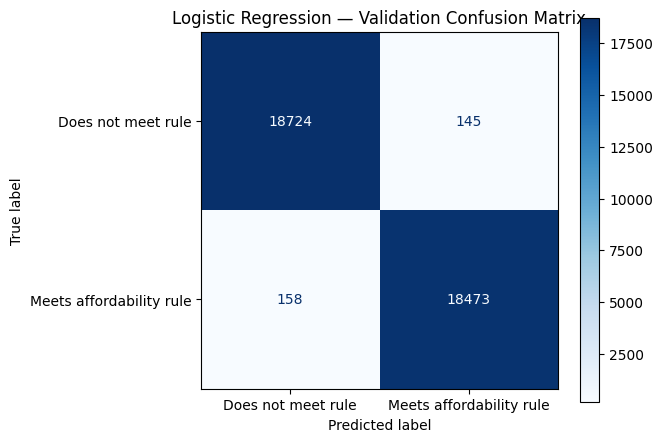

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_validation_class,
    logistic_validation_predictions,
    display_labels=[
        "Does not meet rule",
        "Meets affordability rule"
    ],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest_classifier = Pipeline([
    ("preprocessing", make_preprocessor()),
    (
        "model",
        RandomForestClassifier(
            n_estimators=100,
            max_depth=16,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("Training Random Forest...")

random_forest_classifier.fit(
    X_train,
    y_train_class
)

forest_validation_predictions = random_forest_classifier.predict(
    X_validation
)

record_classification_result(
    "Random forest",
    y_validation_class,
    forest_validation_predictions
)

print("Training complete.")

Training Random Forest...


,Model,Accuracy,Precision,Recall,F1
0,Random forest,0.9793,0.9774,0.9811,0.9792


Training complete.


In [ ]:
# Keep the latest result if an earlier evaluation cell was rerun
classification_comparison = (
    pd.DataFrame(classification_results)
    .drop_duplicates(subset="Model", keep="last")
    .sort_values(
        ["F1", "Accuracy"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(classification_comparison.round(4))

candidate_models = {
    "Logistic regression": logistic_classifier,
    "Random forest": random_forest_classifier
}

candidate_results = classification_comparison[
    classification_comparison["Model"].isin(candidate_models)
]

best_classifier_name = candidate_results.iloc[0]["Model"]
best_classifier = candidate_models[best_classifier_name]

best_f1 = candidate_results.iloc[0]["F1"]

baseline_f1 = classification_comparison.loc[
    classification_comparison["Model"] == "Majority baseline",
    "F1"
].iloc[0]

print("Selected classifier:", best_classifier_name)
print(f"Selected validation F1: {best_f1:.4f}")
print(f"Baseline validation F1: {baseline_f1:.4f}")

if best_f1 <= baseline_f1:
    print("The selected model has not improved on baseline F1.")

,Model,Accuracy,Precision,Recall,F1
0,Logistic regression,0.9919,0.9922,0.9915,0.9919
1,Random forest,0.9793,0.9774,0.9811,0.9792
2,Majority baseline,0.4968,0.4968,1.0000,0.6638


Selected classifier: Logistic regression
Selected validation F1: 0.9919
Baseline validation F1: 0.6638


In [ ]:
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

regression_results = []

def record_regression_result(name, actual, predicted):
    result = {
        "Model": name,
        "MAE_Lakhs": mean_absolute_error(actual, predicted),
        "RMSE_Lakhs": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

    regression_results.append(result)
    display(pd.DataFrame([result]).round(4))


# Baseline 1: predict the training-set mean future price
baseline_regressor = DummyRegressor(strategy="mean")

baseline_regressor.fit(
    X_train[["Price_in_Lakhs"]],
    y_train_reg
)

baseline_reg_predictions = baseline_regressor.predict(
    X_validation[["Price_in_Lakhs"]]
)

record_regression_result(
    "Mean baseline",
    y_validation_reg,
    baseline_reg_predictions
)


# Baseline 2: use the exact formula defining our target
formula_validation_predictions = (
    X_validation["Price_in_Lakhs"]
    * (1 + ASSUMED_ANNUAL_GROWTH) ** PROJECTION_YEARS
)

record_regression_result(
    "Assumed growth formula",
    y_validation_reg,
    formula_validation_predictions
)


# Train Linear Regression using the preprocessing pipeline
linear_regressor = Pipeline([
    ("preprocessing", make_preprocessor()),
    ("model", LinearRegression())
])

linear_regressor.fit(X_train, y_train_reg)

linear_validation_predictions = linear_regressor.predict(
    X_validation
)

record_regression_result(
    "Linear regression",
    y_validation_reg,
    linear_validation_predictions
)

print("\nRegression validation comparison:")
display(pd.DataFrame(regression_results).round(4))

,Model,MAE_Lakhs,RMSE_Lakhs,R2
0,Mean baseline,179.526,207.0798,-0.0


,Model,MAE_Lakhs,RMSE_Lakhs,R2
0,Assumed growth formula,0.0,0.0,1.0


,Model,MAE_Lakhs,RMSE_Lakhs,R2
0,Linear regression,0.0005,0.0006,1.0



Regression validation comparison:


,Model,MAE_Lakhs,RMSE_Lakhs,R2
0,Mean baseline,179.5260,207.0798,-0.0
1,Assumed growth formula,0.0000,0.0000,1.0
2,Linear regression,0.0005,0.0006,1.0


In [ ]:
from sklearn.ensemble import RandomForestRegressor

random_forest_regressor = Pipeline([
    ("preprocessing", make_preprocessor()),
    (
        "model",
        RandomForestRegressor(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("Training Random Forest Regression...")

random_forest_regressor.fit(X_train, y_train_reg)

forest_reg_validation_predictions = (
    random_forest_regressor.predict(X_validation)
)

record_regression_result(
    "Random forest regression",
    y_validation_reg,
    forest_reg_validation_predictions
)

print("Training complete.")

Training Random Forest Regression...


,Model,MAE_Lakhs,RMSE_Lakhs,R2
0,Random forest regression,0.0096,0.0121,1.0


Training complete.


In [ ]:
regression_comparison = (
    pd.DataFrame(regression_results)
    .drop_duplicates(subset="Model", keep="last")
    .sort_values("RMSE_Lakhs")
    .reset_index(drop=True)
)

display(regression_comparison.round(6))

regression_candidates = {
    "Linear regression": linear_regressor,
    "Random forest regression": random_forest_regressor
}

candidate_regression_results = regression_comparison[
    regression_comparison["Model"].isin(regression_candidates)
]

best_regressor_name = candidate_regression_results.iloc[0]["Model"]
best_regressor = regression_candidates[best_regressor_name]

print("Selected regression model:", best_regressor_name)

,Model,MAE_Lakhs,RMSE_Lakhs,R2
0,Assumed growth formula,0.000000,0.000000,1.000000
1,Linear regression,0.000464,0.000574,1.000000
2,Random forest regression,0.009615,0.012124,1.000000
3,Mean baseline,179.526037,207.079816,-0.000016


Selected regression model: Linear regression


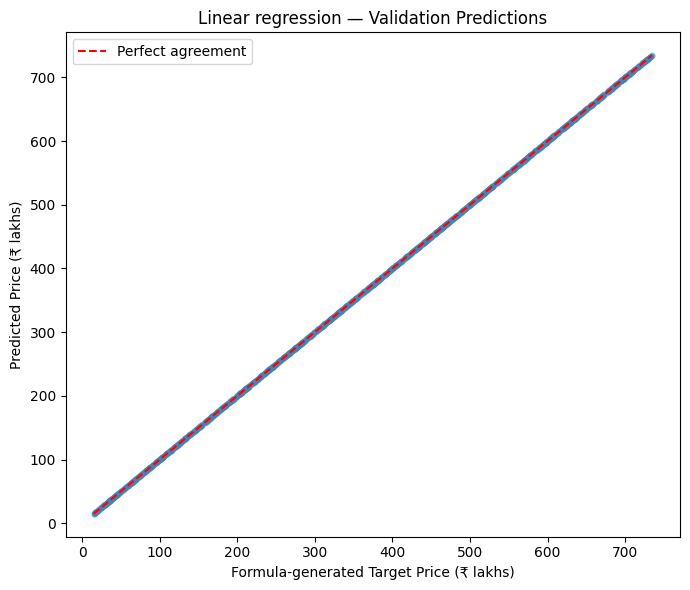

In [ ]:
selected_validation_predictions = best_regressor.predict(
    X_validation
)

# Select 2,000 rows for a readable chart
validation_plot = pd.DataFrame({
    "Target": y_validation_reg.to_numpy(),
    "Prediction": selected_validation_predictions
}).sample(n=2000, random_state=42)

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    validation_plot["Target"],
    validation_plot["Prediction"],
    alpha=0.3,
    s=12,
    color="steelblue"
)

lower = min(
    validation_plot["Target"].min(),
    validation_plot["Prediction"].min()
)

upper = max(
    validation_plot["Target"].max(),
    validation_plot["Prediction"].max()
)

ax.plot(
    [lower, upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="Perfect agreement"
)

ax.set_title(f"{best_regressor_name} — Validation Predictions")
ax.set_xlabel("Formula-generated Target Price (₹ lakhs)")
ax.set_ylabel("Predicted Price (₹ lakhs)")
ax.legend()

plt.tight_layout()
plt.show()

### Regression Model Selection

Linear Regression was selected using validation RMSE.

Its validation MAE was approximately ₹46.40 and RMSE was
₹57.40, lower than Random Forest Regression.

The target was generated from current price using an assumed
8% annual growth rate over five years. Since current price is
an input, the model can closely reproduce this calculation.

These results do not establish accuracy against actual future
property prices. The direct formula reproduces the target exactly.

In [ ]:
print("Classification validation results:")
print(classification_comparison.round(4).to_string(index=False))

print("\nSelected classifier:", best_classifier_name)
print("Selected regressor:", best_regressor_name)

Classification validation results:
              Model  Accuracy  Precision  Recall     F1
Logistic regression    0.9919     0.9922  0.9915 0.9919
      Random forest    0.9793     0.9774  0.9811 0.9792
  Majority baseline    0.4968     0.4968  1.0000 0.6638

Selected classifier: Logistic regression
Selected regressor: Linear regression


In [ ]:
# Predictions from the selected, already-trained models
test_class_predictions = best_classifier.predict(X_test)
test_reg_predictions = best_regressor.predict(X_test)

# Classification test metrics
classification_test_metrics = {
    "Model": best_classifier_name,
    "Accuracy": accuracy_score(
        y_test_class, test_class_predictions
    ),
    "Precision": precision_score(
        y_test_class, test_class_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_class, test_class_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test_class, test_class_predictions, zero_division=0
    )
}

# Regression test metrics — errors measured in lakhs
regression_test_metrics = {
    "Model": best_regressor_name,
    "MAE_Lakhs": mean_absolute_error(
        y_test_reg, test_reg_predictions
    ),
    "RMSE_Lakhs": np.sqrt(
        mean_squared_error(y_test_reg, test_reg_predictions)
    ),
    "R2": r2_score(
        y_test_reg, test_reg_predictions
    )
}

print("FINAL CLASSIFICATION TEST RESULTS")
print(
    pd.DataFrame([classification_test_metrics])
    .round(6)
    .to_string(index=False)
)

print("\nFINAL REGRESSION TEST RESULTS")
print(
    pd.DataFrame([regression_test_metrics])
    .round(8)
    .to_string(index=False)
)

FINAL CLASSIFICATION TEST RESULTS
              Model  Accuracy  Precision   Recall       F1
Logistic regression  0.991467   0.991062 0.991907 0.991484

FINAL REGRESSION TEST RESULTS
            Model  MAE_Lakhs  RMSE_Lakhs  R2
Linear regression   0.000463    0.000573 1.0


                                  precision    recall  f1-score   support

Does not meet affordability rule     0.9919    0.9910    0.9914     18719
        Meets affordability rule     0.9911    0.9919    0.9915     18781

                        accuracy                         0.9915     37500
                       macro avg     0.9915    0.9915    0.9915     37500
                    weighted avg     0.9915    0.9915    0.9915     37500



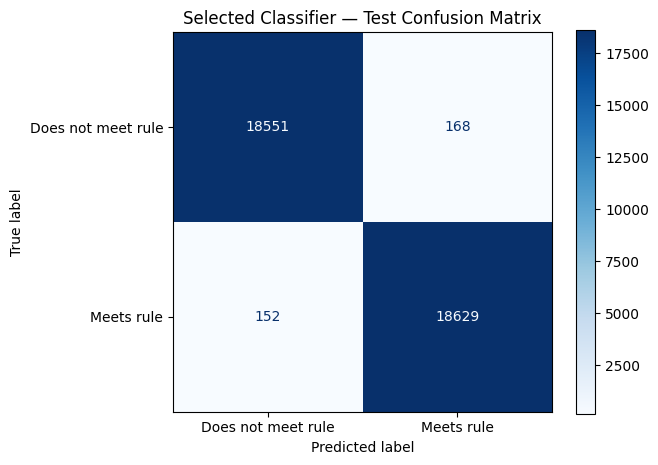

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_class,
        test_class_predictions,
        labels=[0, 1],
        target_names=[
            "Does not meet affordability rule",
            "Meets affordability rule"
        ],
        digits=4,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    test_class_predictions,
    labels=[0, 1],
    display_labels=["Does not meet rule", "Meets rule"],
    cmap="Blues",
    values_format="d"
)

plt.title("Selected Classifier — Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Direct affordability rule
rule_test_predictions = (
    test_df["Price_per_SqFt"]
    <= test_df["Benchmark_Price_per_SqFt"]
).astype(int)

# Direct assumed-growth calculation
formula_test_predictions = (
    X_test["Price_in_Lakhs"]
    * (1 + ASSUMED_ANNUAL_GROWTH) ** PROJECTION_YEARS
)

print(
    "Direct rule accuracy:",
    accuracy_score(y_test_class, rule_test_predictions)
)

print(
    "Direct formula RMSE (lakhs):",
    np.sqrt(
        mean_squared_error(y_test_reg, formula_test_predictions)
    )
)

Direct rule accuracy: 1.0
Direct formula RMSE (lakhs): 0.0


In [ ]:
from pathlib import Path
import joblib
import json
import sklearn
import sys

In [ ]:
metadata = {
    "classifier_name": best_classifier_name,
    "regressor_name": best_regressor_name,
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "benchmark_columns": benchmark_columns,
    "fallback_benchmark": float(fallback_benchmark),
    "assumed_annual_growth": ASSUMED_ANNUAL_GROWTH,
    "projection_years": PROJECTION_YEARS,
    "dataset_reference_year": 2025,
    "price_unit": "INR lakhs",
    "price_per_sqft_unit": "INR per square foot",
    "classification_definition": (
        "Price per square foot at or below the training-set median "
        "for the same state, city and property type."
    ),
    "regression_definition": (
        "Current price compounded at an assumed 8% annually "
        "for five years; not an observed future market price."
    ),
    "python_version": sys.version.split()[0],
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "joblib_version": joblib.__version__
}

with open(project_dir / "models" / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=2)

test_results = {
    "classification": classification_test_metrics,
    "regression": regression_test_metrics
}

with open(project_dir / "reports" / "test_metrics.json", "w") as file:
    json.dump(test_results, file, indent=2)

classification_comparison.to_csv(
    project_dir / "reports" / "classification_validation.csv",
    index=False
)

regression_comparison.to_csv(
    project_dir / "reports" / "regression_validation.csv",
    index=False
)

# Record the split so the experiment can be audited
split_records = pd.concat([
    train_df[["ID"]].assign(Split="train"),
    validation_df[["ID"]].assign(Split="validation"),
    test_df[["ID"]].assign(Split="test")
], ignore_index=True)

split_records.to_csv(
    project_dir / "reports" / "data_split.csv",
    index=False
)

print("Settings, evaluation results and split IDs saved.")

Settings, evaluation results and split IDs saved.


In [ ]:
from pathlib import Path
import joblib

project_dir = Path("/content/Real_Estate_Investment_Advisor")

required_variables = ["best_classifier", "best_regressor"]
missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    print("Missing trained models:", missing)
    print("Run the model training and selection cells first.")
else:
    models_dir = project_dir / "models"
    models_dir.mkdir(parents=True, exist_ok=True)

    joblib.dump(
        best_classifier,
        models_dir / "classification_pipeline.joblib"
    )

    joblib.dump(
        best_regressor,
        models_dir / "regression_pipeline.joblib"
    )

    print("Both model files saved successfully.")

    for path in sorted(models_dir.glob("*.joblib")):
        print(path.name, "—", path.stat().st_size, "bytes")

Both model files saved successfully.
classification_pipeline.joblib — 8762 bytes
regression_pipeline.joblib — 8362 bytes


In [ ]:
from pathlib import Path
import joblib
import numpy as np

project_dir = Path("/content/Real_Estate_Investment_Advisor")

loaded_classifier = joblib.load(
    project_dir / "models" / "classification_pipeline.joblib"
)

loaded_regressor = joblib.load(
    project_dir / "models" / "regression_pipeline.joblib"
)

sample_inputs = X_validation.head(10)

assert np.array_equal(
    best_classifier.predict(sample_inputs),
    loaded_classifier.predict(sample_inputs)
)

assert np.allclose(
    best_regressor.predict(sample_inputs),
    loaded_regressor.predict(sample_inputs),
    rtol=1e-10,
    atol=1e-10
)

print("Saved models loaded successfully.")
print("Predictions match the original models.")

Saved models loaded successfully.
Predictions match the original models.


In [ ]:
import json
import shutil
import sys
import pandas as pd
import sklearn
from google.colab import files

# Create the required folders
for folder in ["models", "data", "reports"]:
    (project_dir / folder).mkdir(parents=True, exist_ok=True)

# Save cleaned data and training-derived benchmarks
df_clean.to_csv(
    project_dir / "data" / "india_housing_prices_cleaned.csv",
    index=False
)

price_benchmarks.to_csv(
    project_dir / "data" / "price_benchmarks.csv",
    index=False
)

# Save the settings needed by the app
metadata = {
    "classifier_name": best_classifier_name,
    "regressor_name": best_regressor_name,
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "benchmark_columns": benchmark_columns,
    "fallback_benchmark": float(fallback_benchmark),
    "assumed_annual_growth": ASSUMED_ANNUAL_GROWTH,
    "projection_years": PROJECTION_YEARS,
    "dataset_reference_year": 2025,
    "price_unit": "INR lakhs",
    "price_per_sqft_unit": "INR per square foot",
    "classification_definition": (
        "Price per square foot at or below the training-set "
        "median for the same state, city and property type."
    ),
    "regression_definition": (
        "Current price compounded at an assumed 8% annually "
        "for five years; not an observed future market price."
    ),
    "python_version": sys.version.split()[0],
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "joblib_version": joblib.__version__
}

with open(
    project_dir / "models" / "metadata.json", "w"
) as file:
    json.dump(metadata, file, indent=2)

# Save evaluation results
with open(
    project_dir / "reports" / "test_metrics.json", "w"
) as file:
    json.dump(
        {
            "classification": classification_test_metrics,
            "regression": regression_test_metrics
        },
        file,
        indent=2
    )

classification_comparison.to_csv(
    project_dir / "reports" / "classification_validation.csv",
    index=False
)

regression_comparison.to_csv(
    project_dir / "reports" / "regression_validation.csv",
    index=False
)

# Save property IDs belonging to each data split
pd.concat([
    train_df[["ID"]].assign(Split="train"),
    validation_df[["ID"]].assign(Split="validation"),
    test_df[["ID"]].assign(Split="test")
], ignore_index=True).to_csv(
    project_dir / "reports" / "data_split.csv",
    index=False
)

# Verify that all essential files exist before creating the ZIP
required_files = [
    "models/classification_pipeline.joblib",
    "models/regression_pipeline.joblib",
    "models/metadata.json",
    "data/india_housing_prices_cleaned.csv",
    "data/price_benchmarks.csv",
    "reports/test_metrics.json",
    "reports/classification_validation.csv",
    "reports/regression_validation.csv",
    "reports/data_split.csv"
]

for filename in required_files:
    path = project_dir / filename
    assert path.is_file() and path.stat().st_size > 0, filename

print("All 9 required files are saved.")

# Create and download the backup
backup_path = shutil.make_archive(
    "/content/Real_Estate_Investment_Advisor_Backup",
    "zip",
    root_dir=str(project_dir.parent),
    base_dir=project_dir.name
)

files.download(backup_path)

print("Backup ZIP is ready. Keep it on your laptop.")

All 9 required files are saved.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Backup ZIP is ready. Keep it on your laptop.


In [ ]:
%pip install -q mlflow

In [ ]:
import mlflow

print("MLflow version:", mlflow.__version__)

MLflow version: 3.17.2


In [ ]:
from pathlib import Path
import mlflow

project_dir = Path("/content/Real_Estate_Investment_Advisor")

# Store experiment records inside the project folder
database_path = project_dir / "mlflow_tracking.db"
artifact_path = project_dir / "mlflow_artifacts"
artifact_path.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{database_path}")

experiment_name = "Real Estate Investment Advisor"

experiment = mlflow.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = mlflow.create_experiment(
        experiment_name,
        artifact_location=artifact_path.as_uri()
    )
else:
    experiment_id = experiment.experiment_id

mlflow.set_experiment(experiment_name)

# Record classification validation results
for _, row in classification_comparison.iterrows():
    with mlflow.start_run(
        run_name=f"Classification validation - {row['Model']}"
    ):
        mlflow.set_tags({
            "task": "classification",
            "evaluation_split": "validation",
            "target_type": "constructed affordability rule"
        })

        mlflow.log_param("model_name", row["Model"])

        mlflow.log_metrics({
            "accuracy": float(row["Accuracy"]),
            "precision": float(row["Precision"]),
            "recall": float(row["Recall"]),
            "f1": float(row["F1"])
        })

# Record regression validation results
for _, row in regression_comparison.iterrows():
    with mlflow.start_run(
        run_name=f"Regression validation - {row['Model']}"
    ):
        mlflow.set_tags({
            "task": "regression",
            "evaluation_split": "validation",
            "target_type": "assumed growth projection"
        })

        mlflow.log_params({
            "model_name": row["Model"],
            "assumed_annual_growth": ASSUMED_ANNUAL_GROWTH,
            "projection_years": PROJECTION_YEARS
        })

        mlflow.log_metrics({
            "mae_lakhs": float(row["MAE_Lakhs"]),
            "rmse_lakhs": float(row["RMSE_Lakhs"]),
            "r2": float(row["R2"])
        })

# Record the selected classifier's final test results
with mlflow.start_run(
    run_name="Selected classifier - final test"
):
    mlflow.set_tags({
        "task": "classification",
        "evaluation_split": "test",
        "target_type": "constructed affordability rule"
    })

    mlflow.log_param("model_name", best_classifier_name)

    mlflow.log_metrics({
        key.lower(): float(value)
        for key, value in classification_test_metrics.items()
        if key != "Model"
    })

    mlflow.log_params({
        key: value
        for key, value in best_classifier.named_steps["model"]
        .get_params(deep=False).items()
    })

    mlflow.log_artifact(
        str(project_dir / "models" / "classification_pipeline.joblib"),
        artifact_path="saved_pipeline"
    )

    mlflow.log_artifact(
        str(project_dir / "models" / "metadata.json"),
        artifact_path="settings"
    )

# Record the selected regressor's final test results
with mlflow.start_run(
    run_name="Selected regressor - final test"
):
    mlflow.set_tags({
        "task": "regression",
        "evaluation_split": "test",
        "target_type": "assumed growth projection"
    })

    mlflow.log_params({
        "model_name": best_regressor_name,
        "assumed_annual_growth": ASSUMED_ANNUAL_GROWTH,
        "projection_years": PROJECTION_YEARS
    })

    mlflow.log_metrics({
        "mae_lakhs": float(regression_test_metrics["MAE_Lakhs"]),
        "rmse_lakhs": float(regression_test_metrics["RMSE_Lakhs"]),
        "r2": float(regression_test_metrics["R2"])
    })

    mlflow.log_params({
        key: value
        for key, value in best_regressor.named_steps["model"]
        .get_params(deep=False).items()
    })

    mlflow.log_artifact(
        str(project_dir / "models" / "regression_pipeline.joblib"),
        artifact_path="saved_pipeline"
    )

print("MLflow experiment records saved successfully.")

# Export a readable experiment summary
runs = mlflow.search_runs(experiment_ids=[experiment_id])

runs.to_csv(
    project_dir / "reports" / "mlflow_runs.csv",
    index=False
)

print("Total recorded runs:", len(runs))

display(
    runs[
        [
            "tags.mlflow.runName",
            "status",
            "metrics.accuracy",
            "metrics.f1",
            "metrics.mae_lakhs",
            "metrics.rmse_lakhs",
            "metrics.r2"
        ]
    ]
)

2026/10/30 17:50:12 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/30 17:50:12 INFO mlflow.store.db.utils: Updating database tables


MLflow experiment records saved successfully.
Total recorded runs: 9


,tags.mlflow.runName,status,metrics.accuracy,metrics.f1,metrics.mae_lakhs,metrics.rmse_lakhs,metrics.r2
0,Selected regressor - final test,FINISHED,NaN,NaN,0.000463,0.000573,1.000000
1,Selected classifier - final test,FINISHED,0.991467,0.991484,NaN,NaN,NaN
2,Regression validation - Mean baseline,FINISHED,NaN,NaN,179.526037,207.079816,-0.000016
3,Regression validation - Random forest regression,FINISHED,NaN,NaN,0.009615,0.012124,1.000000
4,Regression validation - Linear regression,FINISHED,NaN,NaN,0.000464,0.000574,1.000000
5,Regression validation - Assumed growth formula,FINISHED,NaN,NaN,0.000000,0.000000,1.000000
6,Classification validation - Majority baseline,FINISHED,0.496827,0.663840,NaN,NaN,NaN
7,Classification validation - Random forest,FINISHED,0.979333,0.979240,NaN,NaN,NaN
8,Classification validation - Logistic regression,FINISHED,0.991920,0.991866,NaN,NaN,NaN


In [ ]:
import shutil
from google.colab import files

backup_path = shutil.make_archive(
    "/content/Real_Estate_Investment_Advisor_With_MLflow",
    "zip",
    root_dir=str(project_dir.parent),
    base_dir=project_dir.name
)

files.download(backup_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>